# GridWorld enhancement 3: dynamic exploration over all pairs (OMC) + count-based optimism

**IE 692.** This notebook follows the same protocol as the baseline, E1, and E2:

1. **Shared settings.** $\gamma$, the minimum history $T=100$, the observation budget
   (15M), and the baseline's stepsize are read from `results/gridworld_baseline.npz`.
2. **Tuning.** Each candidate is run once (first seed) with **10% of the budget**. The score
   is the exact optimality gap at state 0 of the last policy obtained within that budget.
3. **Full runs.** The tuned settings are run on the five seeds in `SEEDS`, with
   **15M observations** each.
4. **Evaluation.** Every learned policy is evaluated exactly with the Bellman equation.
   We report $V^{\pi_k}(0)-V^*(0)$ and the gap averaged over all 100 states, as
   mean ± 95% CI over seeds. The model is used for evaluation only.
5. **Saving.** Runs are saved with `save_runs` to `results/gridworld_enh3_*.npz`, in
   the baseline's format. The baseline curve is loaded from its file and is not rerun.

**What E3 changes.** E3 changes *how experience is collected* (proposal, E3):

| | Baseline (TOMC) | E3 control: OMC, $\beta=0$ | E3: OMC + bonus |
|---|---|---|---|
| Pairs that must be visited before an update | $\pi_k(a\mid s)\ge 0.025$ | all 400 | all 400 |
| $\widehat Q$ of a rarely chosen action | fallback $1/(1-\gamma)=10$ | its sampled return | its sampled return |
| Score used in the KL update | $\widehat Q_k$ | $\widehat Q_k$ | $\widehat Q_k-b_k$ |

The bonus uses cumulative visit counts:
$$b_k(s,a)=\beta\sqrt{\frac{2\ln(2+N_k(s))}{1+N_k(s,a)}},\qquad N_k(s)=\sum_a N_k(s,a).$$

The KL update depends on $\eta(\widehat Q_k-b_k)=\eta\widehat Q_k-\eta\beta\,g_k$, so the
bonus strength is the product $\eta\beta$. A $\beta$ that suits one stepsize is too
strong or too weak for another. We therefore tune $\eta$ for the control ($\beta=0$)
and $(\eta,\beta)$ jointly for the bonus variant, over the baseline's stepsize candidates.

**How to run:** keep `gridworld_results.py` in the same folder, run
`gridworld_baseline.ipynb` first, then run the cells from top to bottom (a few
minutes; Numba compiles the sampler on first use). On Colab, upload
`gridworld_results.py` and `results/gridworld_baseline.npz` (into a `results`
folder) first. Dependencies: NumPy, pandas, Matplotlib, and Numba (installed if
missing).

In [2]:
import importlib.util
import subprocess
import sys

# Install Numba only if it is missing; do not upgrade working packages.
if importlib.util.find_spec("numba") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "numba"])

import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.ticker import FuncFormatter, MaxNLocator, NullFormatter
import numba
from numba import njit

from gridworld_results import (
    SEEDS, BASELINE_COLOR, SERIES_COLORS, INK, MUTED, optimal_values, save_runs, load_runs,
    sample_grid, on_grid, mean_ci, format_mean_ci, apply_plot_style, plot_band, save_figure,
)

print(f"Python {sys.version.split()[0]} | NumPy {np.__version__} | Numba {numba.__version__}")

Python 3.12.16 | NumPy 2.5.5 | Numba 0.68.1


## 1. Settings and a fixed map

Rows and columns start at zero; state `s = 10 * row + column`. State 0 is the origin
and reporting state. Arrays use **[state, action]**.

`GAMMA`, `HISTORY_LENGTH`, the observation budget, and the baseline's stepsize come from
the baseline file. `ETA_CANDIDATES` are the baseline's candidates. `BETA_CANDIDATES`
contains the no-bonus control ($\beta=0$). The earlier E3 draft also tried $\beta=100$;
it is not repeated because that run stalled after one or two updates even at $\eta=0.1$.

`PI_THRESHOLD` = 0.025 is used **only** to reproduce the baseline (Section 6). The E3
collection rule and estimator never use it.

In [3]:
# The baseline supplies the shared settings and the comparison curve.
baseline_runs, baseline_settings = load_runs("gridworld_baseline")

GAMMA = 0.9
BASELINE_ETA = float(baseline_settings["eta"])                # Tuned in the baseline notebook.
SAMPLE_BUDGET = int(baseline_settings["sample_budget"])       # Observations in one full run.
TUNING_BUDGET = SAMPLE_BUDGET // 10                           # Each tuning run gets 10%.
HISTORY_LENGTH = int(baseline_settings["history_length"])     # Minimum cost terms after a first visit.
ETA_CANDIDATES = (0.1, 1.0, 2.0, 10.0)                        # The baseline's stepsize candidates.
BETA_CANDIDATES = (0.0, 0.1, 1.0, 10.0)                       # beta = 0 is the no-bonus control.

P_INTENDED = 0.8
Q_MOVE = 0.2              # At a goal/hazard: move with .2, return to origin with .8.
C_GOAL, C_REGULAR, C_HAZARD = 0.0, 0.2, 1.0

LAYOUT = (
    "O........G",
    "..H....H..",
    ".....H....",
    ".H......H.",
    "..........",
    "...H.G....",
    "......H...",
    ".H........",
    "....H...H.",
    ".........G",
)
grid = np.array([list(row) for row in LAYOUT])
N_ROWS, N_COLS = grid.shape
N_STATES, N_ACTIONS = grid.size, 4
PI_THRESHOLD = (1 - GAMMA) / N_ACTIONS   # Baseline reproduction ONLY; never used by E3.
GOALS = set(np.flatnonzero(grid.ravel() == "G"))
HAZARDS = set(np.flatnonzero(grid.ravel() == "H"))
ORIGIN = int(np.flatnonzero(grid.ravel() == "O")[0])
REPORT_STATE = ORIGIN

ACTION_NAMES = ("up", "right", "down", "left")
DIRECTIONS = ((-1, 0), (0, 1), (1, 0), (0, -1))

assert grid.shape == (10, 10)
assert len(GOALS) == 3 and len(HAZARDS) == 10
assert np.count_nonzero(grid == "O") == 1
assert ORIGIN not in GOALS | HAZARDS and GOALS.isdisjoint(HAZARDS)
assert float(baseline_settings["gamma"]) == GAMMA
assert int(baseline_settings["report_state"]) == REPORT_STATE
assert HISTORY_LENGTH == 100 and TUNING_BUDGET > 0
assert BASELINE_ETA in ETA_CANDIDATES
assert 0.0 in BETA_CANDIDATES and all(b >= 0 for b in BETA_CANDIDATES)

print(f"Budget per run: {SAMPLE_BUDGET:,} observations; tuning: {TUNING_BUDGET:,} per candidate.")
print(f"Baseline stepsize: eta = {BASELINE_ETA:g}; seeds: {list(SEEDS)}")

Budget per run: 15,000,000 observations; tuning: 1,500,000 per candidate.
Baseline stepsize: eta = 1; seeds: [0, 1, 2, 3, 4]


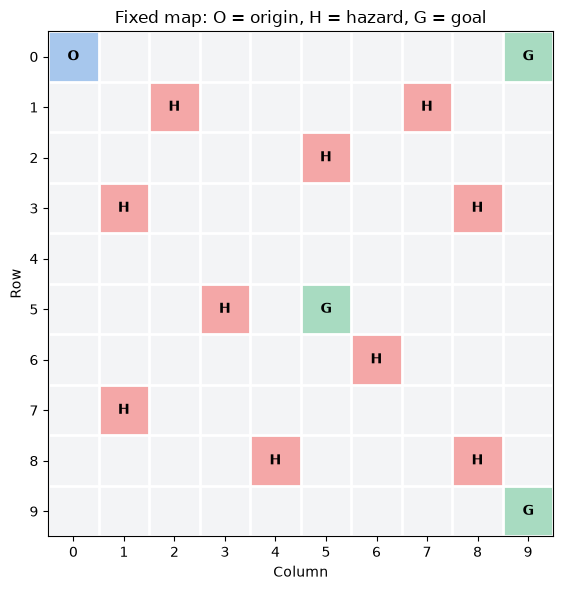

In [4]:
# The colors and letters show the fixed environment, not a learned policy.
colors = {".": 0, "H": 1, "G": 2, "O": 3}
map_colors = np.array([[colors[cell] for cell in row] for row in grid])
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(map_colors, cmap=ListedColormap(["#f3f4f6", "#f4a7a7", "#a8dbc1", "#a7c7ed"]),
          vmin=0, vmax=3)
for (row, col), cell in np.ndenumerate(grid):
    if cell != ".":
        ax.text(col, row, cell, ha="center", va="center", fontweight="bold")
ax.set(xticks=range(N_COLS), yticks=range(N_ROWS), xlabel="Column", ylabel="Row",
       title="Fixed map: O = origin, H = hazard, G = goal")
ax.set_xticks(np.arange(-0.5, N_COLS, 1), minor=True)
ax.set_yticks(np.arange(-0.5, N_ROWS, 1), minor=True)
ax.grid(which="minor", color="white", linewidth=2)
ax.tick_params(which="minor", bottom=False, left=False)
plt.tight_layout()
plt.show()

## 2. Environment: give an action, receive (cost, next state)

Same rules as the baseline. Ordinary motion follows the intended direction with
probability 0.8 and each other direction with probability $0.2/3$; a move through a
wall stays in place. The cost is charged at the **current state before moving**: goal 0,
hazard 1, ordinary cell 0.2. From a goal or hazard the next step returns to the origin
with probability 0.8. Goals and hazards are not terminal.

`GridWorld` below is the baseline's simulator, kept as the **reference**. The runs use a
compiled copy of the same rules (Section 3); Section 5 checks that both produce
identical trajectories from the same random generator.

In [5]:
def move(state, direction):
    # Attempt one direction; clipping implements the wall rule.
    row, col = divmod(state, N_COLS)
    dr, dc = DIRECTIONS[direction]
    row = min(max(row + dr, 0), N_ROWS - 1)
    col = min(max(col + dc, 0), N_COLS - 1)
    return row * N_COLS + col


class GridWorld:
    # The baseline's simulator, used as the reference in the checks.
    def __init__(self):
        self.state = ORIGIN
        self.move_probs = np.full((N_ACTIONS, N_ACTIONS), (1 - P_INTENDED) / 3)
        np.fill_diagonal(self.move_probs, P_INTENDED)

    def step(self, action, rng):
        state = self.state
        cost = C_GOAL if state in GOALS else C_HAZARD if state in HAZARDS else C_REGULAR
        if state in GOALS | HAZARDS and rng.random() < 1 - Q_MOVE:
            next_state = ORIGIN
        else:
            direction = rng.choice(N_ACTIONS, p=self.move_probs[action])
            next_state = move(state, direction)
        self.state = next_state
        return cost, next_state

## 3. Dynamic collection under a frozen policy

Let $\mathcal E_k$ be the pairs that must be visited and $\tau_k(s,a)$ the first-visit
index in the current batch. Collection stops at
$$n_k=\max_{(s,a)\in\mathcal E_k}\tau_k(s,a)+T,\qquad T=100.$$

- **E3 (OMC):** $\mathcal E_k=\mathcal S\times\mathcal A$, all 400 pairs, whatever their probability.
- **Baseline (TOMC):** $\mathcal E_k=\{(s,a):\pi_k(a\mid s)\ge 0.025\}$, used here only to reproduce the baseline.

The policy is frozen during a batch and the state continues from the previous batch.

**Budget.** A batch may not run past the remaining budget. If it is cut off before every
required pair has its 100-term history, its observations count toward the budget but no
Q table or update is produced. This gives the same result as the team's rule: the
reported policy is the last one obtained within the budget. (The baseline lets its last
batch overshoot and then ignores the policy produced after the budget.) The cap also
matters for OMC, which can otherwise wait indefinitely for a pair whose probability is
nearly zero.

In [6]:
@njit
def draw_from_cdf(cdf, rng):
    # One uniform draw with NumPy choice's rule: the first index whose CDF exceeds u.
    u = rng.random()
    for a in range(len(cdf)):
        if u < cdf[a]:
            return a
    return len(cdf) - 1


@njit
def collect_online(policy_cdf, required, start_state, history_length,
                   observation_limit, rng, state_costs, special_states,
                   next_by_direction, move_cdf, q_move, origin):
    # Collect one frozen-policy batch, or stop at the remaining budget.
    first = np.full(required.shape, -1, dtype=np.int64)
    visits = np.zeros(required.shape, dtype=np.int64)
    costs = np.empty(observation_limit, dtype=np.float64)
    missing = np.sum(required)
    stop_after = -1
    state = start_state

    for t in range(observation_limit):
        action = draw_from_cdf(policy_cdf[state], rng)
        costs[t] = state_costs[state]          # Charge at the CURRENT state, before moving.
        visits[state, action] += 1
        if first[state, action] < 0:
            first[state, action] = t
            if required[state, action]:
                missing -= 1
                if missing == 0:
                    stop_after = t + history_length   # C_t is the first of T terms.

        if special_states[state] and rng.random() < 1.0 - q_move:
            state = origin
        else:
            direction = draw_from_cdf(move_cdf[action], rng)
            state = next_by_direction[state, direction]

        n = t + 1
        if stop_after >= 0 and n >= stop_after:
            return costs[:n].copy(), visits, first, state, True

    # Budget exhausted: NOT a completed Monte Carlo evaluation.
    return costs, visits, first, state, False


def make_sampling_tables():
    # Array form of the simulator rules, built from move() and GridWorld.
    state_costs = np.full(N_STATES, C_REGULAR)
    state_costs[list(GOALS)] = C_GOAL
    state_costs[list(HAZARDS)] = C_HAZARD
    special = np.zeros(N_STATES, dtype=np.bool_)
    special[list(GOALS | HAZARDS)] = True
    destinations = np.array([[move(s, d) for d in range(N_ACTIONS)] for s in range(N_STATES)],
                            dtype=np.int64)
    cdf = np.cumsum(GridWorld().move_probs, axis=1)
    cdf /= cdf[:, -1:]
    return state_costs, special, destinations, cdf


STATE_COSTS, SPECIAL_STATES, DESTINATIONS, MOVE_CDF = make_sampling_tables()


def validate_policy(policy):
    policy = np.asarray(policy, dtype=float)
    if policy.ndim != 2 or min(policy.shape) == 0:
        raise ValueError("policy must be a nonempty [state, action] array")
    if not np.isfinite(policy).all() or (policy < 0).any():
        raise ValueError("policy probabilities must be finite and nonnegative")
    if not np.allclose(policy.sum(axis=1), 1.0, rtol=0, atol=1e-12):
        raise ValueError("each policy row must sum to one")
    return policy


def required_mask(policy, evaluation):
    # OMC requires every pair; TOMC (baseline reproduction only) uses the 0.025 threshold.
    policy = validate_policy(policy)
    if evaluation == "omc":
        return np.ones(policy.shape, dtype=np.bool_)
    if evaluation == "tomc":
        return policy >= PI_THRESHOLD
    raise ValueError("evaluation must be 'omc' or 'tomc'")


def collect_batch(policy, start_state, rng, remaining_budget, evaluation="omc",
                  history_length=HISTORY_LENGTH):
    required = required_mask(policy, evaluation)
    if not isinstance(history_length, (int, np.integer)) or history_length < 1:
        raise ValueError("history_length must be a positive integer")
    if not isinstance(remaining_budget, (int, np.integer)) or remaining_budget < 1:
        raise ValueError("remaining_budget must be a positive integer")
    if not 0 <= start_state < N_STATES:
        raise ValueError("invalid starting state")
    cdf = np.cumsum(policy, axis=1)
    cdf /= cdf[:, -1:]
    return collect_online(cdf, required, int(start_state), int(history_length),
                          int(remaining_budget), rng, STATE_COSTS, SPECIAL_STATES,
                          DESTINATIONS, MOVE_CDF, Q_MOVE, ORIGIN)

## 4. Estimator, bonus, policy update, and the learning loop

**OMC estimator (E3).** Every pair receives its full first-visit suffix
$$\widehat Q_k(s,a)=\sum_{t=\tau_k(s,a)}^{n_k-1}\gamma^{t-\tau_k(s,a)}C_t,$$
with no probability threshold and no fallback. A missing or short history is an error.

**TOMC estimator (baseline reproduction only).** The same suffix for pairs with
$\pi_k(a\mid s)\ge0.025$, and $1/(1-\gamma)$ for the rest.

**Update.** After a completed batch, cumulative counts give $b_k$ and
$$\pi_{k+1}(a\mid s)=\frac{\pi_k(a\mid s)e^{-\eta(\widehat Q_k(s,a)-b_k(s,a))}}
{\sum_{a'}\pi_k(a'\mid s)e^{-\eta(\widehat Q_k(s,a')-b_k(s,a'))}}.$$
The recorded estimate $\widehat V_k(0)=\sum_a\pi_k(a\mid0)\widehat Q_k(0,a)$ uses the raw
$\widehat Q_k$, never the bonus-adjusted score. With $\beta=0$ the update is the baseline's
KL-SPMD update.

The loop also records, for each batch, the **smallest probability among the pairs that
batch had to visit**. A batch cannot end before its rarest required pair appears, so this
number explains the batch lengths (Section 9).

In [7]:
@njit
def full_suffix_returns(costs, gamma):
    returns = np.zeros(len(costs) + 1)
    for t in range(len(costs) - 1, -1, -1):
        returns[t] = costs[t] + gamma * returns[t + 1]
    return returns


def validate_return_inputs(costs, first, gamma, history_length):
    costs, first = np.asarray(costs, dtype=float), np.asarray(first)
    if not 0 <= gamma < 1:
        raise ValueError("gamma must lie in [0, 1)")
    if not isinstance(history_length, (int, np.integer)) or history_length < 1:
        raise ValueError("history_length must be a positive integer")
    if first.ndim != 2 or not np.issubdtype(first.dtype, np.integer):
        raise ValueError("first visits must be an integer [state, action] table")
    if costs.ndim != 1 or not np.isfinite(costs).all():
        raise ValueError("costs must be a finite vector")
    complete = (first >= 0) & (len(costs) - first >= history_length)
    return costs, first, complete


def estimate_omc(costs, first, gamma=GAMMA, history_length=HISTORY_LENGTH):
    # Every Q entry is a real first-visit return: no threshold, no fallback.
    costs, first, complete = validate_return_inputs(costs, first, gamma, history_length)
    if not complete.all():
        raise ValueError("Incomplete OMC batch: every pair needs its full cost history")
    return full_suffix_returns(costs, gamma)[first].copy()


def estimate_tomc(costs, first, policy, gamma=GAMMA, history_length=HISTORY_LENGTH):
    # The baseline's estimator; used only to reproduce the baseline.
    costs, first, complete = validate_return_inputs(costs, first, gamma, history_length)
    required = required_mask(policy, "tomc")
    if first.shape != policy.shape or not complete[required].all():
        raise ValueError("Incomplete TOMC batch")
    q_hat = np.full(policy.shape, 1.0 / (1.0 - gamma))
    q_hat[required] = full_suffix_returns(costs, gamma)[first[required]]
    return q_hat


def estimate_q(costs, first, policy, evaluation, gamma=GAMMA, history_length=HISTORY_LENGTH):
    if first.shape != policy.shape:
        raise ValueError("first visits and policy must have matching shapes")
    if evaluation == "omc":
        return estimate_omc(costs, first, gamma, history_length)
    return estimate_tomc(costs, first, policy, gamma, history_length)


def kl_spmd_update(policy, scores, eta):
    # The baseline's KL update for cost minimization.
    scores = -eta * scores
    scores -= scores.max(axis=1, keepdims=True)
    weights = policy * np.exp(scores)
    return weights / weights.sum(axis=1, keepdims=True)


def ucb_bonus(cumulative_visits, beta):
    counts = np.asarray(cumulative_visits)
    if counts.ndim != 2 or not np.isfinite(counts).all() or (counts < 0).any():
        raise ValueError("counts must be a finite nonnegative 2D table")
    if not np.isfinite(beta) or beta < 0:
        raise ValueError("beta must be finite and nonnegative")
    if beta == 0:
        return np.zeros(counts.shape, dtype=float)
    state_visits = counts.sum(axis=1, keepdims=True)
    return beta * np.sqrt(2.0 * np.log(2.0 + state_visits) / (1.0 + counts))


def update_with_bonus(policy, q_hat, counts, beta, eta):
    # Sampled Q values stay intact; optimism enters only the update score.
    if not np.isfinite(eta) or eta < 0:
        raise ValueError("eta must be finite and nonnegative")
    if q_hat.shape != policy.shape or not np.isfinite(q_hat).all():
        raise ValueError("q_hat must be finite and match the policy")
    if counts.shape != policy.shape:
        raise ValueError("counts must match the policy")
    bonus = ucb_bonus(counts, beta)
    new_policy = kl_spmd_update(policy, q_hat - bonus, eta)
    if not np.isfinite(new_policy).all():
        raise FloatingPointError("Nonfinite policy; reduce beta or eta")
    validate_policy(new_policy)
    return new_policy, bonus

In [8]:
def run_e3(eta, beta, seed, observation_budget, evaluation="omc",
           gamma=GAMMA, history_length=HISTORY_LENGTH):
    # One online run with an exact observation budget. Training never sees the model.
    if not isinstance(observation_budget, (int, np.integer)) or observation_budget < 1:
        raise ValueError("observation_budget must be a positive integer")
    if not 0 <= gamma < 1 or not np.isfinite(eta) or eta < 0:
        raise ValueError("invalid gamma or eta")
    if evaluation not in ("omc", "tomc"):
        raise ValueError("unknown evaluation method")
    if evaluation == "tomc" and beta != 0:
        raise ValueError("The TOMC reproduction never receives a bonus")
    ucb_bonus(np.zeros((1, 1), dtype=np.int64), beta)   # Validate beta before sampling.

    rng = np.random.default_rng(seed)
    policy = np.full((N_STATES, N_ACTIONS), 1.0 / N_ACTIONS)
    counts = np.zeros(policy.shape, dtype=np.int64)       # Cumulative visits, fresh per run.
    state, spent = ORIGIN, 0
    policies, samples = [policy.copy()], [0]              # pi_0 exists at zero observations.
    estimates, batch_lengths, min_required_prob, bonus_spread_state0 = [], [], [], []
    unfinished = 0
    started = time.perf_counter()

    while spent < observation_budget:
        costs, visits, first, state, complete = collect_batch(
            policy, state, rng, observation_budget - spent, evaluation, history_length)
        n = len(costs)
        spent += n
        counts += visits                                  # Every interaction is counted.
        assert visits.sum() == n and counts.sum() == spent
        if not complete:
            unfinished = n                                # Counted, but no partial update.
            break

        required = required_mask(policy, evaluation)
        q_hat = estimate_q(costs, first, policy, evaluation, gamma, history_length)
        assert n == first[required].max() + history_length
        assert (n - first[required]).min() == history_length

        estimates.append(float(policy[REPORT_STATE] @ q_hat[REPORT_STATE]))
        batch_lengths.append(n)
        min_required_prob.append(float(policy[required].min()))
        policy, bonus = update_with_bonus(policy, q_hat, counts, beta, eta)
        bonus_spread_state0.append(float(np.ptp(bonus[REPORT_STATE])))
        policies.append(policy.copy())
        samples.append(spent)

    assert spent <= observation_budget
    return {"evaluation": evaluation, "eta": float(eta), "beta": float(beta), "seed": int(seed),
            "policies": np.array(policies), "samples": np.array(samples, dtype=np.int64),
            "estimates": np.array(estimates), "batch_lengths": np.array(batch_lengths, dtype=np.int64),
            "min_required_prob": np.array(min_required_prob),
            "bonus_spread_state0": np.array(bonus_spread_state0),
            "cumulative_visits": counts, "observations_spent": spent,
            "unfinished_observations": unfinished,
            "seconds": time.perf_counter() - started}

## 5. Exact evaluation and checks

Build the transition model from the map, independently of the simulator, and use it
**only to measure** learned policies:
$$V^{\pi}=(I-\gamma P_\pi)^{-1}c,\qquad
V^*(s)=\min_a\Big[c(s)+\gamma\sum_{s'}P(s'\mid s,a)V^*(s')\Big].$$
$V^*$ must equal the one saved by the baseline, so both notebooks describe the same MDP.
`summarize_run` stores each run in the baseline's format: `samples[i]` observations were
used to obtain policy $i$, and `values[i]` is that policy's exact value at every state.

In [9]:
def build_exact_model():
    # Independent construction: does not call move(), GridWorld.step(), or sampling tables.
    P = np.zeros((N_STATES, N_ACTIONS, N_STATES))
    c = np.empty(N_STATES)
    for s in range(N_STATES):
        row, col = divmod(s, N_COLS)
        cell = grid[row, col]
        c[s] = {"G": C_GOAL, "H": C_HAZARD}.get(cell, C_REGULAR)
        special = cell in ("G", "H")
        move_weight = Q_MOVE if special else 1.0
        for a in range(N_ACTIONS):
            if special:
                P[s, a, ORIGIN] += 1.0 - Q_MOVE
            for d, (dr, dc) in enumerate(((-1, 0), (0, 1), (1, 0), (0, -1))):
                r, j = row + dr, col + dc
                next_s = r * N_COLS + j if 0 <= r < N_ROWS and 0 <= j < N_COLS else s
                probability = P_INTENDED if d == a else (1.0 - P_INTENDED) / 3.0
                P[s, a, next_s] += move_weight * probability
    assert (P >= 0).all()
    np.testing.assert_allclose(P.sum(axis=2), 1.0, atol=1e-12)
    return P, c


P_EXACT, C_EXACT = build_exact_model()
V_STAR = optimal_values(P_EXACT, C_EXACT, GAMMA)
np.testing.assert_allclose(V_STAR, baseline_settings["V_star"], atol=1e-9)   # Same MDP as the baseline.


def policy_values(policy):
    # Exact V^pi at every state; costs depend only on the state, so c_pi = c.
    P_pi = np.sum(policy[:, :, None] * P_EXACT, axis=1)
    values = np.linalg.solve(np.eye(N_STATES) - GAMMA * P_pi, C_EXACT)
    np.testing.assert_allclose(values, C_EXACT + GAMMA * P_pi @ values, atol=1e-10)
    return values


V_UNIFORM = policy_values(np.full((N_STATES, N_ACTIONS), 1 / N_ACTIONS))


def gap_at_report_state(values):
    # Optimality gap at the reporting state for a stack of value vectors [n, state].
    return values[:, REPORT_STATE] - V_STAR[REPORT_STATE]


def mean_gap(values):
    # Optimality gap averaged over all 100 start states.
    return (values - V_STAR).mean(axis=1)


def summarize_run(run):
    # Baseline format, plus two E3 diagnostics.
    values = np.array([policy_values(pi) for pi in run["policies"]])
    assert (values >= V_STAR - 1e-9).all()
    return {
        "seed": run["seed"],
        "samples": run["samples"],                         # samples[i] observations -> policy i.
        "values": values,                                  # Exact V of policy i at every state.
        "estimate": np.append(run["estimates"], np.nan),   # The last policy is never evaluated.
        "observations": run["batch_lengths"],              # Completed batches only.
        "seconds": run["seconds"],
        "final_policy": run["policies"][-1],
        "min_required_prob": run["min_required_prob"],     # E3 diagnostic (Section 9).
        "unfinished_observations": run["unfinished_observations"],
    }


print(f"Uniform policy: V(0) = {V_UNIFORM[REPORT_STATE]:.4f}")
print(f"Optimal policy: V*(0) = {V_STAR[REPORT_STATE]:.4f}  (matches the baseline file)")

Uniform policy: V(0) = 2.3672
Optimal policy: V*(0) = 2.0043  (matches the baseline file)


The checks below verify: the exact model against every simulator branch; the compiled
sampler against the baseline's `GridWorld` (same costs, first visits, counts, endpoint,
and number of random draws); that rare actions get real OMC returns with no fallback;
all-pair stopping; the bonus and update; and budget handling. Validation observations
are not part of any experiment budget.

In [10]:
class ControlledRNG:
    # Forces one simulator branch: a fixed reset draw and a fixed direction.
    def __init__(self, reset_draw, direction):
        self.reset_draw, self.direction = reset_draw, direction

    def random(self):
        return self.reset_draw

    def choice(self, n, p):
        return self.direction


def check_model_against_simulator():
    env = GridWorld()
    simulated = np.zeros_like(P_EXACT)
    for s in range(N_STATES):
        motion = Q_MOVE if s in GOALS | HAZARDS else 1.0
        for a in range(N_ACTIONS):
            if s in GOALS | HAZARDS:
                env.state = s
                cost, next_state = env.step(a, ControlledRNG(0.0, 0))
                assert cost == C_EXACT[s] and next_state == ORIGIN
                simulated[s, a, next_state] += 1.0 - motion
            for d in range(N_ACTIONS):
                env.state = s
                cost, next_state = env.step(a, ControlledRNG(1.0, d))
                assert cost == C_EXACT[s] and cost == STATE_COSTS[s]
                assert next_state == DESTINATIONS[s, d]
                simulated[s, a, next_state] += motion * env.move_probs[a, d]
    np.testing.assert_allclose(simulated, P_EXACT, atol=1e-14)
    print("PASS: exact model and sampling tables match every simulator branch.")


def check_sampler_against_reference():
    policies = [np.full((N_STATES, N_ACTIONS), .25),
                np.random.default_rng(456).dirichlet(np.ones(N_ACTIONS), size=N_STATES)]
    for i, pi in enumerate(policies):
        reference_rng, fast_rng = np.random.default_rng(700 + i), np.random.default_rng(700 + i)
        env = GridWorld()
        env.state = 22                                   # A hazard start: costs and reset draws.
        costs, visits, first, end, complete = collect_batch(pi, 22, fast_rng, 3000)
        states, actions, reference_costs = [22], [], []
        for _ in range(len(costs)):
            action = int(reference_rng.choice(N_ACTIONS, p=pi[states[-1]]))
            cost, next_state = env.step(action, reference_rng)
            actions.append(action)
            reference_costs.append(cost)
            states.append(next_state)
        np.testing.assert_array_equal(costs, reference_costs)
        ref_visits, ref_first = np.zeros_like(visits), np.full_like(first, -1)
        for t, (s, a) in enumerate(zip(states[:-1], actions)):
            ref_visits[s, a] += 1
            if ref_first[s, a] < 0:
                ref_first[s, a] = t
        np.testing.assert_array_equal(visits, ref_visits)
        np.testing.assert_array_equal(first, ref_first)
        assert end == env.state
        assert reference_rng.random() == fast_rng.random()   # Same number of random draws.
    print("PASS: compiled sampler reproduces the baseline simulator draw for draw.")


def expect_value_error(call):
    try:
        call()
    except ValueError:
        return
    raise AssertionError("Expected rejection of invalid or incomplete input")


def check_omc_without_fallback():
    pi = np.array([[.001, .499, .25, .25]])
    first = np.array([[0, 1, 2, 3]], dtype=np.int64)
    costs = np.array([.1, .2, .3, .4, .5, .6])
    q = estimate_q(costs, first, pi, "omc", GAMMA, 3)
    expected = np.array([[sum(GAMMA**j * c for j, c in enumerate(costs[t:])) for t in first[0]]])
    np.testing.assert_allclose(q, expected, atol=1e-14)
    assert required_mask(pi, "omc").all() and q[0, 0] < 10
    # Which action is rare has no effect on any OMC entry.
    np.testing.assert_array_equal(estimate_q(costs, first, pi[:, [1, 0, 2, 3]], "omc", GAMMA, 3), q)
    # The baseline reproduction keeps its fallback for the rare action.
    np.testing.assert_allclose(estimate_tomc(costs, first, pi, GAMMA, 3)[0, 0], 10)
    missing = first.copy()
    missing[0, 0] = -1
    expect_value_error(lambda: estimate_omc(costs, missing, GAMMA, 3))
    estimate_tomc(costs, missing, pi, GAMMA, 3)        # Allowed for TOMC, never for OMC.
    short = first.copy()
    short[0, 0] = 4
    expect_value_error(lambda: estimate_omc(costs, short, GAMMA, 3))
    # The entire suffix is used, including costs after term 100.
    long_costs = np.zeros(103)
    long_costs[101] = 1.0
    np.testing.assert_allclose(estimate_omc(long_costs, first, GAMMA, 100), GAMMA**(101 - first),
                               atol=0, rtol=1e-12)
    print("PASS: rare actions get real OMC returns; no threshold, no fallback, full suffixes.")


def check_all_pair_stopping():
    pi = np.array([[.98, .01, .005, .005]])
    one_state = (np.array([.2]), np.array([False]), np.zeros((1, 4), dtype=np.int64), MOVE_CDF, .2, 0)
    required = required_mask(pi, "omc")
    costs, visits, first, _, complete = collect_online(np.cumsum(pi, axis=1), required, 0, 100,
                                                       10000, np.random.default_rng(3), *one_state)
    assert complete and (visits > 0).all() and len(costs) == first.max() + 100
    np.testing.assert_allclose(estimate_omc(costs, first),
                               .2 * (1 - GAMMA**(len(costs) - first)) / (1 - GAMMA), atol=1e-12)
    # One observation fewer is incomplete, although every pair was visited.
    cut = collect_online(np.cumsum(pi, axis=1), required, 0, 100, len(costs) - 1,
                         np.random.default_rng(3), *one_state)
    assert not cut[-1]
    expect_value_error(lambda: estimate_omc(cut[0], cut[2]))
    # A zero-probability action is never filled with a synthetic value.
    deterministic = np.array([[1., 0., 0., 0.]])
    stuck = collect_online(np.cumsum(deterministic, axis=1), required_mask(deterministic, "omc"),
                           0, 100, 150, np.random.default_rng(4), *one_state)
    assert not stuck[-1] and len(stuck[0]) == 150
    expect_value_error(lambda: estimate_omc(stuck[0], stuck[2]))
    expect_value_error(lambda: run_e3(1.0, 1.0, 0, 50, evaluation="tomc"))
    print("PASS: all-pair coverage, exact stopping, rejection of missing/short histories.")


def check_bonus_and_update():
    rng = np.random.default_rng(5)
    pi = rng.dirichlet(np.ones(4), size=6)
    q = rng.uniform(0, 10, size=pi.shape)
    counts = rng.integers(0, 2000, size=pi.shape)
    before = [pi.copy(), q.copy(), counts.copy()]
    zero, bonus0 = update_with_bonus(pi, q, counts, 0., 0.7)
    np.testing.assert_array_equal(zero, kl_spmd_update(pi, q, 0.7))
    np.testing.assert_array_equal(bonus0, 0)
    np.testing.assert_allclose(update_with_bonus(pi, q, counts, 100., 0.)[0], pi)
    updated, bonus = update_with_bonus(pi, q, counts, 10., 0.7)
    terms = pi * np.exp(-0.7 * (q - bonus))
    np.testing.assert_allclose(updated, terms / terms.sum(axis=1, keepdims=True))
    np.testing.assert_allclose(update_with_bonus(pi, q + 13., counts, 10., 0.7)[0], updated)
    # Only eta * beta matters: (eta, beta) and (eta / 10, 10 beta) give the same bonus term.
    a = kl_spmd_update(pi, -ucb_bonus(counts, 10.), 0.1)
    b = kl_spmd_update(pi, -ucb_bonus(counts, 1.), 1.0)
    np.testing.assert_allclose(a, b, atol=1e-13)
    for x, y in zip((pi, q, counts), before):
        np.testing.assert_array_equal(x, y)
    # A less-visited action gains probability; equal counts change nothing.
    flat = np.full((1, 4), .25)
    updated, bonus = update_with_bonus(flat, np.full((1, 4), 2.), np.array([[0, 100, 100, 100]]), 1., 1.)
    assert bonus[0, 0] > bonus[0, 1] and updated[0, 0] > updated[0, 1]
    np.testing.assert_allclose(update_with_bonus(flat, np.full((1, 4), 2.), np.full((1, 4), 100), 50., 1.)[0], flat)
    print("PASS: beta = 0, bonus sign, eta = 0, row shifts, eta*beta invariance, no mutation.")


def check_budget_handling():
    # Fewer observations than the minimum history: no update is possible.
    run = run_e3(1.0, 1.0, 17, 50)
    assert run["observations_spent"] == 50 and len(run["samples"]) == 1
    assert run["unfinished_observations"] == 50 and run["cumulative_visits"].sum() == 50
    np.testing.assert_allclose(run["policies"][-1], .25)
    # Same seed, same run.
    again = run_e3(1.0, 1.0, 17, 50)
    np.testing.assert_array_equal(run["cumulative_visits"], again["cumulative_visits"])
    # A policy becomes available at the end of its batch, never earlier (team's on_grid rule).
    artificial = {"samples": np.array([0, 100, 200]), "values": np.array([[3.], [2.5], [2.]])}
    np.testing.assert_array_equal(on_grid(artificial, np.array([0, 99, 100, 199, 200, 250]),
                                          lambda v: v[:, 0]), [3., 3., 2.5, 2.5, 2., 2.])
    print("PASS: strict budgets, no partial updates, reproducible runs, policy timing.")


check_model_against_simulator()
check_sampler_against_reference()
check_omc_without_fallback()
check_all_pair_stopping()
check_bonus_and_update()
check_budget_handling()
print("All checks passed.")

PASS: exact model and sampling tables match every simulator branch.
PASS: compiled sampler reproduces the baseline simulator draw for draw.
PASS: rare actions get real OMC returns; no threshold, no fallback, full suffixes.
PASS: all-pair coverage, exact stopping, rejection of missing/short histories.
PASS: beta = 0, bonus sign, eta = 0, row shifts, eta*beta invariance, no mutation.
PASS: strict budgets, no partial updates, reproducible runs, policy timing.
All checks passed.


## 6. Reproduce the saved baseline with the same code

Running this notebook's code with the TOMC rule and the baseline's $\eta$ should give the
saved baseline runs exactly: the same random generator per seed, the same batch ends,
and the same exact values. A match confirms that E3 differs from the baseline **only**
in the collection rule and the bonus, and that seeds are paired across notebooks (each
seed starts with the identical first batch). These runs also supply the baseline's
batch diagnostics in Section 9. They are not used for learning or tuning.

If the files do not match (for example, a different NumPy version changed the random
stream), every comparison below is still valid; the seeds are then independent rather
than paired.

In [11]:
reproduction, rows = {}, []
for base in baseline_runs:
    seed = int(base["seed"])
    summary = summarize_run(run_e3(BASELINE_ETA, 0.0, seed, SAMPLE_BUDGET, evaluation="tomc"))
    reproduction[seed] = summary
    inside = base["samples"] <= SAMPLE_BUDGET
    same_samples = np.array_equal(base["samples"][inside], summary["samples"])
    same_values = same_samples and np.allclose(base["values"][inside], summary["values"], atol=1e-9)
    rows.append({"seed": seed, "baseline_updates_in_budget": int(inside.sum()) - 1,
                 "reproduced_updates": len(summary["samples"]) - 1,
                 "identical_batch_ends": same_samples, "identical_exact_values": same_values})
reproduction_table = pd.DataFrame(rows)
print(reproduction_table.to_string(index=False))
BASELINE_REPRODUCED = bool(reproduction_table["identical_exact_values"].all())
print("\nPASS: the saved baseline is reproduced exactly; seeds are paired across notebooks."
      if BASELINE_REPRODUCED else
      "\nNOTE: not reproduced exactly; comparisons remain valid, but seeds are not paired.")

 seed  baseline_updates_in_budget  reproduced_updates  identical_batch_ends  identical_exact_values
    0                          20                  20                  True                    True
    1                          26                  26                  True                    True
    2                          31                  31                  True                    True
    3                          20                  20                  True                    True
    4                          27                  27                  True                    True

PASS: the saved baseline is reproduced exactly; seeds are paired across notebooks.


## 7. Tune with 10% of the budget

Each $(\eta,\beta)$ combination is run once (first seed) with `TUNING_BUDGET`
observations. As in the baseline, the score is the exact gap at state 0 of the last
policy obtained within that budget.

- **OMC control:** the best $\eta$ in the $\beta=0$ row.
- **OMC + bonus:** the best $(\eta,\beta)$ with $\beta>0$.

`policy_updates` counts completed updates; `unfinished` is the size of a final batch that
the budget cut off. A large unfinished batch means collection stalled while waiting for
a rare pair.

In [12]:
tuning_rows = []
for beta in BETA_CANDIDATES:
    for eta in ETA_CANDIDATES:
        run = run_e3(eta, beta, SEEDS[0], TUNING_BUDGET)
        final = policy_values(run["policies"][-1])[None]   # Last policy within the budget.
        tuning_rows.append({
            "beta": beta, "eta": eta, "policy_updates": len(run["samples"]) - 1,
            "gap_at_state_0": gap_at_report_state(final)[0],
            "mean_gap_all_states": mean_gap(final)[0],
            "unfinished": run["unfinished_observations"],
        })
tuning = pd.DataFrame(tuning_rows)

control_best = tuning.loc[tuning.loc[tuning["beta"] == 0, "gap_at_state_0"].idxmin()]
bonus_best = tuning.loc[tuning.loc[tuning["beta"] > 0, "gap_at_state_0"].idxmin()]
CONFIGS = {
    "omc_tuned": {"eta": float(control_best["eta"]), "beta": 0.0},
    "omc_bonus_tuned": {"eta": float(bonus_best["eta"]), "beta": float(bonus_best["beta"])},
}
LABELS = {
    "omc_tuned": f"OMC, β = 0 (η = {CONFIGS['omc_tuned']['eta']:g})",
    "omc_bonus_tuned": (f"OMC + bonus (η = {CONFIGS['omc_bonus_tuned']['eta']:g}, "
                        f"β = {CONFIGS['omc_bonus_tuned']['beta']:g})"),
}

print(f"Tuning budget: {TUNING_BUDGET:,} observations per combination (seed {SEEDS[0]}).\n")
print("Gap at state 0 (rows: beta, columns: eta)")
print(tuning.pivot(index="beta", columns="eta", values="gap_at_state_0").round(4).to_string())
print("\nCompleted policy updates")
print(tuning.pivot(index="beta", columns="eta", values="policy_updates").to_string())
print(f"\nOMC control: eta = {CONFIGS['omc_tuned']['eta']:g}")
print(f"OMC + bonus: eta = {CONFIGS['omc_bonus_tuned']['eta']:g}, beta = {CONFIGS['omc_bonus_tuned']['beta']:g}"
      f"  (eta * beta = {CONFIGS['omc_bonus_tuned']['eta'] * CONFIGS['omc_bonus_tuned']['beta']:g})")

Tuning budget: 1,500,000 observations per combination (seed 0).

Gap at state 0 (rows: beta, columns: eta)
eta     0.1     1.0     2.0     10.0
beta                                
0.0   0.3474  0.1748  0.2125  0.2868
0.1   0.3474  0.1720  0.2853  0.2868
1.0   0.3443  0.1407  0.1838  0.2870
10.0  0.3482  0.3084  0.2859  0.2893

Completed policy updates
eta   0.1   1.0   2.0   10.0
beta                        
0.0      3     4     2     1
0.1      3     4     1     1
1.0      3     5     3     1
10.0     3     1     1     1

OMC control: eta = 1
OMC + bonus: eta = 1, beta = 1  (eta * beta = 1)


## 8. Full runs on five seeds

Each tuned configuration runs on every seed with the baseline's budget. Each run starts a
fresh environment at state 0 with its own generator and fresh visit counts. Summaries are
saved as `results/gridworld_enh3_omc_tuned.npz` and
`results/gridworld_enh3_omc_bonus_tuned.npz`, in the baseline's format.

In [13]:
enh3_runs = {}
for name, config in CONFIGS.items():
    enh3_runs[name] = []
    for seed in SEEDS:
        summary = summarize_run(run_e3(config["eta"], config["beta"], seed, SAMPLE_BUDGET))
        enh3_runs[name].append(summary)
        print(f"{name}, seed {seed}: {len(summary['samples']) - 1} updates, "
              f"last update at {summary['samples'][-1]:,}, "
              f"unfinished tail {summary['unfinished_observations']:,}", flush=True)
    path = save_runs(
        f"gridworld_enh3_{name}", enh3_runs[name], **config,
        gamma=GAMMA, sample_budget=SAMPLE_BUDGET, history_length=HISTORY_LENGTH,
        report_state=REPORT_STATE,
    )
    print(f"Saved {path}")

omc_tuned, seed 0: 8 updates, last update at 6,459,487, unfinished tail 8,540,513
omc_tuned, seed 1: 8 updates, last update at 8,684,124, unfinished tail 6,315,876
omc_tuned, seed 2: 10 updates, last update at 13,809,986, unfinished tail 1,190,014
omc_tuned, seed 3: 7 updates, last update at 10,051,761, unfinished tail 4,948,239
omc_tuned, seed 4: 7 updates, last update at 5,438,431, unfinished tail 9,561,569
Saved results/gridworld_enh3_omc_tuned.npz
omc_bonus_tuned, seed 0: 13 updates, last update at 14,336,957, unfinished tail 663,043
omc_bonus_tuned, seed 1: 10 updates, last update at 10,566,396, unfinished tail 4,433,604
omc_bonus_tuned, seed 2: 13 updates, last update at 13,643,396, unfinished tail 1,356,604
omc_bonus_tuned, seed 3: 13 updates, last update at 11,446,134, unfinished tail 3,553,866
omc_bonus_tuned, seed 4: 11 updates, last update at 9,879,913, unfinished tail 5,120,087
Saved results/gridworld_enh3_omc_bonus_tuned.npz


## 9. Results: E3 versus the baseline

The table reports the last policy obtained within the budget. Gaps are means over five
seeds with 95% confidence intervals. `reaches_baseline_gap` counts the seeds whose gap at
state 0 falls to the baseline's final mean gap within the budget, and the mean number of
observations they needed.

The second table compares methods **seed by seed** (same seed, same first batch).
Negative differences mean the first method is better.

In [14]:
METHODS = {
    "Baseline: SPMD + TOMC": (baseline_runs, BASELINE_COLOR),
    LABELS["omc_tuned"]: (enh3_runs["omc_tuned"], SERIES_COLORS[1]),
    LABELS["omc_bonus_tuned"]: (enh3_runs["omc_bonus_tuned"], SERIES_COLORS[0]),
}
BUDGET = np.array([SAMPLE_BUDGET])


def final_metric(runs, metric):
    return np.array([on_grid(run, BUDGET, metric)[0] for run in runs])


def samples_to_reach(run, target_gap):
    inside = run["samples"] <= SAMPLE_BUDGET
    hit = np.flatnonzero(gap_at_report_state(run["values"][inside]) <= target_gap)
    return run["samples"][hit[0]] if hit.size else np.nan


baseline_final_gap = final_metric(baseline_runs, gap_at_report_state).mean()
summary_rows = []
for label, (runs, _) in METHODS.items():
    reached = np.array([samples_to_reach(run, baseline_final_gap) for run in runs], dtype=float)
    ok = reached[np.isfinite(reached)]
    summary_rows.append({
        "method": label,
        "updates_in_budget": np.mean([np.searchsorted(run["samples"], SAMPLE_BUDGET, side="right") - 1
                                      for run in runs]),
        "gap_at_state_0": format_mean_ci(final_metric(runs, gap_at_report_state)),
        "mean_gap_all_states": format_mean_ci(final_metric(runs, mean_gap)),
        "reaches_baseline_gap": (f"{len(ok)}/{len(runs)} seeds, {ok.mean():,.0f} obs."
                                 if len(ok) else f"0/{len(runs)} seeds"),
    })
summary = pd.DataFrame(summary_rows)
print(f"Budget {SAMPLE_BUDGET:,} observations per run, {len(SEEDS)} seeds. "
      f"Uniform policy: gap at state 0 = {V_UNIFORM[REPORT_STATE] - V_STAR[REPORT_STATE]:.4f}.")
print(f"Baseline's final mean gap at state 0: {baseline_final_gap:.4f}\n")
print(summary.to_string(index=False))


def by_seed(runs):
    return {int(run["seed"]): run for run in runs}


paired_rows = []
for label, first_runs, second_runs in (
    ("OMC + bonus  minus  baseline", enh3_runs["omc_bonus_tuned"], baseline_runs),
    ("OMC, beta = 0  minus  baseline", enh3_runs["omc_tuned"], baseline_runs),
    ("OMC + bonus  minus  OMC, beta = 0", enh3_runs["omc_bonus_tuned"], enh3_runs["omc_tuned"]),
):
    a, b = by_seed(first_runs), by_seed(second_runs)
    assert sorted(a) == sorted(b) == sorted(SEEDS)
    a, b = [a[s] for s in SEEDS], [b[s] for s in SEEDS]
    d0 = final_metric(a, gap_at_report_state) - final_metric(b, gap_at_report_state)
    dm = final_metric(a, mean_gap) - final_metric(b, mean_gap)
    paired_rows.append({"comparison": label,
                        "difference_gap_state_0": format_mean_ci(d0),
                        "difference_mean_gap": format_mean_ci(dm),
                        "seeds_better_at_state_0": f"{int((d0 < 0).sum())}/{len(d0)}"})
print("\nPaired by seed (95% CI of the mean difference):")
print(pd.DataFrame(paired_rows).to_string(index=False))

Budget 15,000,000 observations per run, 5 seeds. Uniform policy: gap at state 0 = 0.3629.
Baseline's final mean gap at state 0: 0.0553

                    method  updates_in_budget  gap_at_state_0 mean_gap_all_states      reaches_baseline_gap
     Baseline: SPMD + TOMC               24.8 0.0553 ± 0.0147     0.1003 ± 0.0139 2/5 seeds, 6,423,738 obs.
        OMC, β = 0 (η = 1)                8.0 0.0862 ± 0.0272     0.1524 ± 0.0143                 0/5 seeds
OMC + bonus (η = 1, β = 1)               12.0 0.0649 ± 0.0142     0.1384 ± 0.0091 1/5 seeds, 9,879,913 obs.

Paired by seed (95% CI of the mean difference):
                       comparison difference_gap_state_0 difference_mean_gap seeds_better_at_state_0
     OMC + bonus  minus  baseline        0.0096 ± 0.0144     0.0381 ± 0.0192                     2/5
   OMC, beta = 0  minus  baseline        0.0309 ± 0.0260     0.0521 ± 0.0128                     0/5
OMC + bonus  minus  OMC, beta = 0       -0.0213 ± 0.0190    -0.0140 ± 0.0203    

**Left.** Optimality gap at state 0 against cumulative observations (mean ± 95% CI).
**Right.** Gap at the end of the budget: one dot per seed, with the mean and its 95% CI.

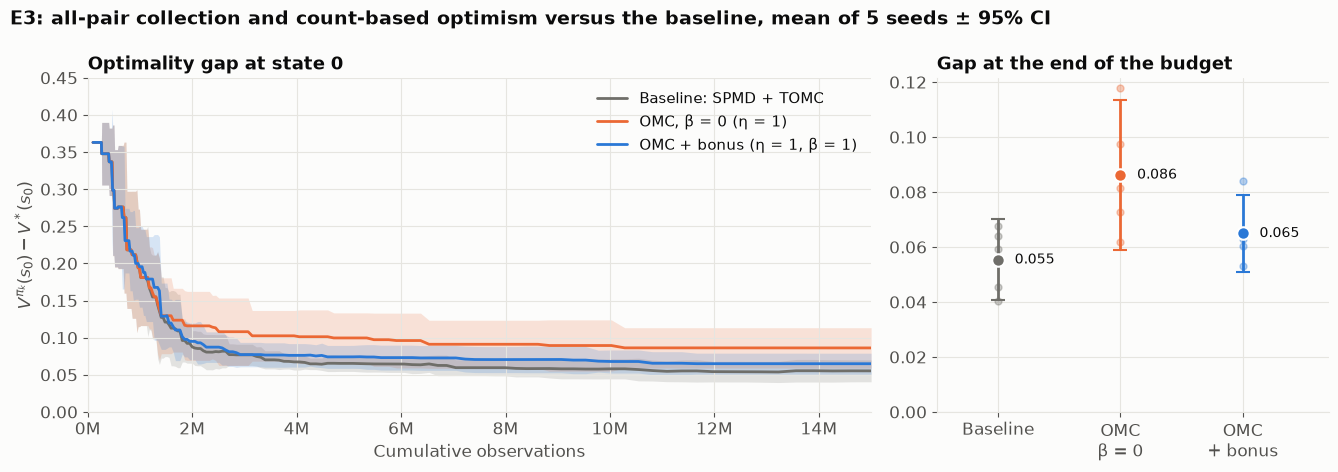

In [15]:
apply_plot_style()
millions = FuncFormatter(lambda x, _: f"{x / 1e6:g}M")
grid_samples = sample_grid(SAMPLE_BUDGET, first=100_000)
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), gridspec_kw={"width_ratios": [2, 1]})

ax = axes[0]
for label, (runs, color) in METHODS.items():
    curves = [on_grid(run, grid_samples, gap_at_report_state) for run in runs]
    plot_band(ax, grid_samples, curves, color, label)
ax.set(title="Optimality gap at state 0", xlabel="Cumulative observations",
       ylabel=r"$V^{\pi_k}(s_0) - V^*(s_0)$", xlim=(0, SAMPLE_BUDGET), ylim=(0, 0.45))
ax.xaxis.set_major_formatter(millions)
ax.legend(loc="upper right")

ax = axes[1]
for position, (label, (runs, color)) in enumerate(METHODS.items()):
    gaps = final_metric(runs, gap_at_report_state)
    mean, half_width = mean_ci(gaps[:, None])
    ax.plot(np.full(len(gaps), position), gaps, "o", color=color, alpha=0.35, markersize=5)
    ax.errorbar(position, mean[0], yerr=half_width[0], fmt="o", color=color, markersize=9,
                markeredgecolor="white", markeredgewidth=1.5, capsize=5, elinewidth=2)
    ax.annotate(f"{mean[0]:.3f}", (position, mean[0]), xytext=(12, 0),
                textcoords="offset points", va="center", color=INK, fontsize=10)
ax.set(title="Gap at the end of the budget", xlim=(-0.5, len(METHODS) - 0.3), ylim=(0, None))
ax.set_xticks(range(len(METHODS)), ["Baseline", "OMC\nβ = 0", "OMC\n+ bonus"])
fig.suptitle(f"E3: all-pair collection and count-based optimism versus the baseline, "
             f"mean of {len(SEEDS)} seeds ± 95% CI", x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.tight_layout()
save_figure(fig, "e3_results")
plt.show()

**Same results on logarithmic axes**, in the format of the E1 figure. Left: the
reporting state. Right: the gap averaged over all 100 states.

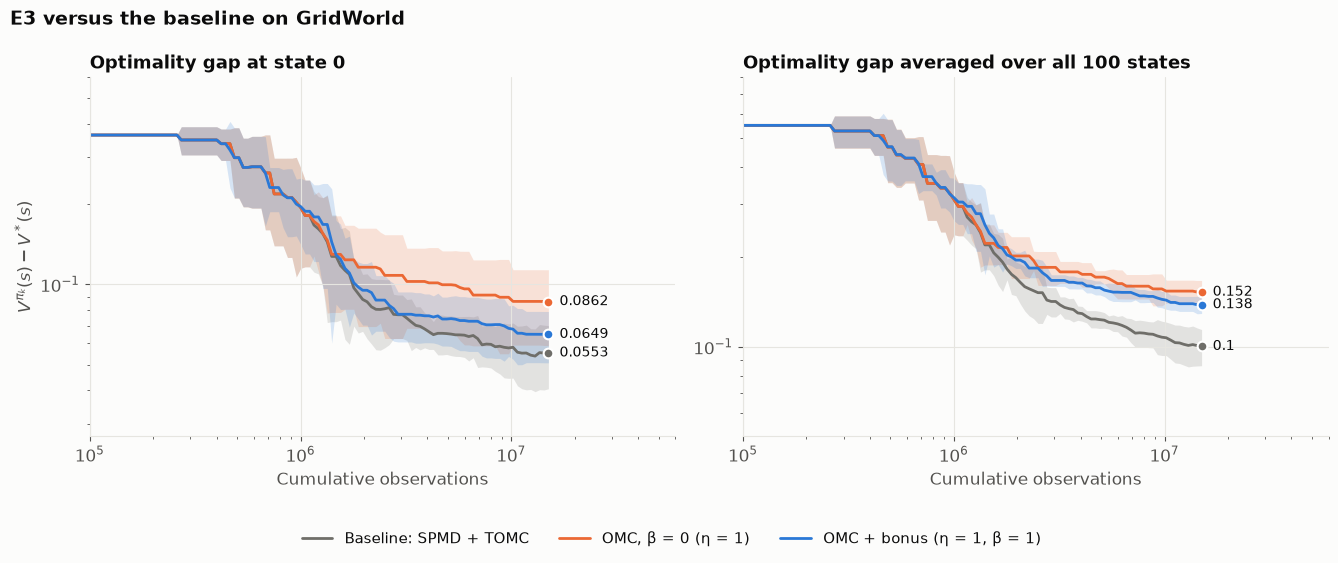

In [16]:
apply_plot_style()
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.4), sharex=True)
panels = ((gap_at_report_state, "Optimality gap at state 0", 0.6),
          (mean_gap, "Optimality gap averaged over all 100 states", 0.8))
log_grid = sample_grid(SAMPLE_BUDGET)
for ax, (metric, title, top) in zip(axes, panels):
    lowest = np.inf
    for label, (runs, color) in METHODS.items():
        curves = [on_grid(run, log_grid, metric) for run in runs]
        mean = plot_band(ax, log_grid, curves, color, label)
        lowest = min(lowest, mean[mean > 0].min())
        ax.plot(log_grid[-1], mean[-1], "o", color=color, markersize=7,
                markeredgecolor="white", markeredgewidth=1.5)
        ax.annotate(f"{mean[-1]:.3g}", (log_grid[-1], mean[-1]), xytext=(8, 0),
                    textcoords="offset points", va="center", color=INK, fontsize=10)
    ax.set(title=title, xscale="log", xlabel="Cumulative observations")
    ax.set_yscale("log", nonpositive="clip")
    ax.set_ylim(lowest / 2, top)
    ax.yaxis.set_minor_formatter(NullFormatter())
axes[0].set_ylabel(r"$V^{\pi_k}(s) - V^*(s)$")
axes[0].set_xlim(1e5, 6e7)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.04))
fig.suptitle("E3 versus the baseline on GridWorld", x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.tight_layout(rect=(0, 0.06, 1, 1))
save_figure(fig, "e3_results_log")
plt.show()

### Why: a batch waits for its rarest required pair

**Left.** Observations per batch for every seed (log scale). **Right.** Each dot is one
batch: its length against the smallest policy probability among the pairs it had to
visit. TOMC never waits for a pair below 0.025. OMC must wait for every pair, so its
batches grow as the policy commits to its preferred actions. A moderate bonus slows the
decay of rarely chosen actions, so more batches finish within the budget. Too large a
bonus does the opposite: one update concentrates each state's policy on its least-visited
action, the other actions become rare, and the next batch cannot finish (see
$\beta=10$ in Section 10). Baseline points come from the reproduction runs of Section 6,
so they stop at the budget.

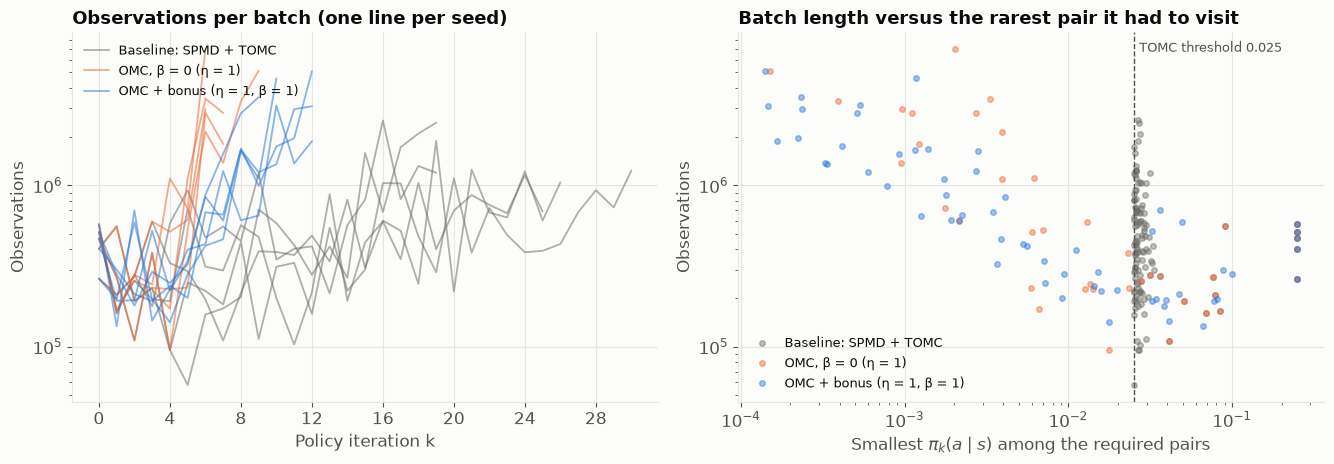

In [17]:
apply_plot_style()
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
mechanism = {"Baseline: SPMD + TOMC": (list(reproduction.values()), BASELINE_COLOR)}
mechanism.update({label: value for label, value in METHODS.items() if label != "Baseline: SPMD + TOMC"})
for label, (runs, color) in mechanism.items():
    for i, run in enumerate(runs):
        k = np.arange(len(run["observations"]))
        axes[0].plot(k, run["observations"], color=color, alpha=0.55, linewidth=1.3,
                     label=label if i == 0 else None)
        axes[1].plot(run["min_required_prob"], run["observations"], "o", color=color, alpha=0.45,
                     markersize=4, label=label if i == 0 else None)
axes[0].set(title="Observations per batch (one line per seed)", xlabel="Policy iteration k",
            ylabel="Observations", yscale="log")
axes[1].axvline(PI_THRESHOLD, color=MUTED, linestyle="--", linewidth=1)
axes[1].annotate("TOMC threshold 0.025", xy=(PI_THRESHOLD, 1.0), xycoords=("data", "axes fraction"),
                 xytext=(4, -14), textcoords="offset points", color=MUTED, fontsize=9)
axes[1].set(title="Batch length versus the rarest pair it had to visit",
            xlabel=r"Smallest $\pi_k(a\mid s)$ among the required pairs", ylabel="Observations",
            xscale="log", yscale="log")
axes[0].xaxis.set_major_locator(MaxNLocator(integer=True))
axes[0].legend(loc="upper left", fontsize=9)
axes[1].legend(loc="lower left", fontsize=9)
fig.tight_layout()
save_figure(fig, "e3_batch_lengths")
plt.show()

## 10. Bonus strength at the baseline's stepsize

To compare with E2, which uses the baseline's $\eta$ throughout, every $\beta$ is also run
at $\eta$ = `BASELINE_ETA` on all five seeds. This shows the effect of the bonus alone, at
the stepsize the baseline uses. Saved as `results/gridworld_enh3_eta<η>_beta<β>.npz`.

eta = 1 for every row, budget 15,000,000, 5 seeds
               method  updates_in_budget  gap_at_state_0 mean_gap_all_states
Baseline: SPMD + TOMC               24.8 0.0553 ± 0.0147     0.1003 ± 0.0139
           OMC, β = 0                8.0 0.0862 ± 0.0272     0.1524 ± 0.0143
         OMC, β = 0.1                9.4 0.0726 ± 0.0202     0.1360 ± 0.0162
           OMC, β = 1               12.0 0.0649 ± 0.0142     0.1384 ± 0.0091
          OMC, β = 10                1.4 0.2598 ± 0.0555     0.4132 ± 0.0463


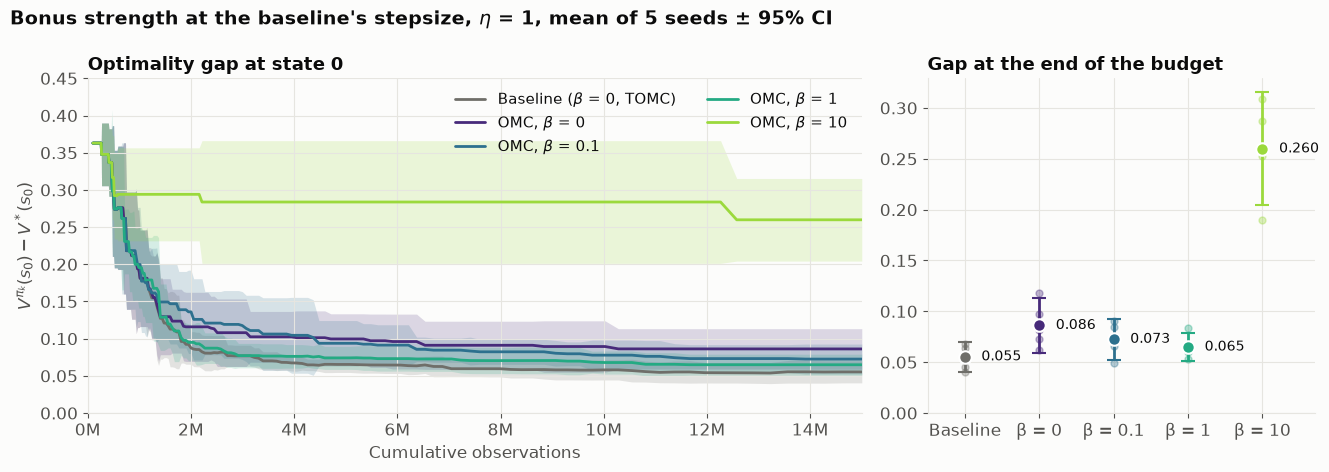

In [18]:
sensitivity = {}
for beta in BETA_CANDIDATES:
    sensitivity[beta] = [summarize_run(run_e3(BASELINE_ETA, beta, seed, SAMPLE_BUDGET)) for seed in SEEDS]
    save_runs(f"gridworld_enh3_eta{BASELINE_ETA:g}_beta{beta:g}", sensitivity[beta],
              eta=BASELINE_ETA, beta=beta, gamma=GAMMA, sample_budget=SAMPLE_BUDGET,
              history_length=HISTORY_LENGTH, report_state=REPORT_STATE)

sensitivity_rows = [{
    "method": "Baseline: SPMD + TOMC",
    "updates_in_budget": np.mean([np.searchsorted(r["samples"], SAMPLE_BUDGET, side="right") - 1
                                  for r in baseline_runs]),
    "gap_at_state_0": format_mean_ci(final_metric(baseline_runs, gap_at_report_state)),
    "mean_gap_all_states": format_mean_ci(final_metric(baseline_runs, mean_gap)),
}]
for beta, runs in sensitivity.items():
    sensitivity_rows.append({
        "method": f"OMC, β = {beta:g}",
        "updates_in_budget": np.mean([len(r["samples"]) - 1 for r in runs]),
        "gap_at_state_0": format_mean_ci(final_metric(runs, gap_at_report_state)),
        "mean_gap_all_states": format_mean_ci(final_metric(runs, mean_gap)),
    })
print(f"eta = {BASELINE_ETA:g} for every row, budget {SAMPLE_BUDGET:,}, {len(SEEDS)} seeds")
print(pd.DataFrame(sensitivity_rows).to_string(index=False))

apply_plot_style()
sens_colors = plt.cm.viridis(np.linspace(0.12, 0.85, len(BETA_CANDIDATES)))
SENS_METHODS = {"Baseline ($\\beta$ = 0, TOMC)": (baseline_runs, BASELINE_COLOR)}
for beta, color in zip(BETA_CANDIDATES, sens_colors):
    SENS_METHODS[f"OMC, $\\beta$ = {beta:g}"] = (sensitivity[beta], color)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), gridspec_kw={"width_ratios": [2, 1]})
for label, (runs, color) in SENS_METHODS.items():
    curves = [on_grid(run, grid_samples, gap_at_report_state) for run in runs]
    plot_band(axes[0], grid_samples, curves, color, label)
axes[0].set(title="Optimality gap at state 0", xlabel="Cumulative observations",
            ylabel=r"$V^{\pi_k}(s_0) - V^*(s_0)$", xlim=(0, SAMPLE_BUDGET), ylim=(0, 0.45))
axes[0].xaxis.set_major_formatter(millions)
axes[0].legend(loc="upper right", ncol=2)
for position, (label, (runs, color)) in enumerate(SENS_METHODS.items()):
    gaps = final_metric(runs, gap_at_report_state)
    mean, half_width = mean_ci(gaps[:, None])
    axes[1].plot(np.full(len(gaps), position), gaps, "o", color=color, alpha=0.35, markersize=5)
    axes[1].errorbar(position, mean[0], yerr=half_width[0], fmt="o", color=color, markersize=9,
                     markeredgecolor="white", markeredgewidth=1.5, capsize=5, elinewidth=2)
    axes[1].annotate(f"{mean[0]:.3f}", (position, mean[0]), xytext=(12, 0),
                     textcoords="offset points", va="center", color=INK, fontsize=10)
axes[1].set(title="Gap at the end of the budget", xlim=(-0.5, len(SENS_METHODS) - 0.3), ylim=(0, None))
axes[1].set_xticks(range(len(SENS_METHODS)),
                   ["Baseline"] + [f"β = {beta:g}" for beta in BETA_CANDIDATES])
fig.suptitle(f"Bonus strength at the baseline's stepsize, $\\eta$ = {BASELINE_ETA:g}, "
             f"mean of {len(SEEDS)} seeds ± 95% CI", x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.tight_layout()
save_figure(fig, "e3_beta_sensitivity")
plt.show()

In [ ]:
# Compare V^pi - V^* by policy-update index, rather than by cumulative observations.

fig, ax = plt.subplots(figsize=(8, 5))
for label, (runs, color) in METHODS.items():
    run_gaps = [gap_at_report_state(run["values"]) for run in runs]
    for gaps in run_gaps:
        ax.plot(np.arange(len(gaps)), gaps, color=color, alpha=0.3)
    mean_gaps = np.array([
        np.mean([gaps[update] for gaps in run_gaps if update < len(gaps)])
        for update in range(max(map(len, run_gaps)))
    ])
    ax.plot(np.arange(len(mean_gaps)), mean_gaps, color=color, label=label, linewidth=2)
ax.set(title="Optimality gap at state 0 by policy update",
       xlabel="Completed policy updates (0 = initial policy)",
       ylabel=r"$V^{\pi_k}(s_0) - V^*(s_0)$")
ax.set_yscale("log")
ax.legend()
save_figure(fig, "e3_policy_update_gap")        

## 11. Where each method is right

The gap $V^{\pi}(s)-V^*(s)$ of the final policy at every state (mean over seeds), in the
format of the E1 maps. The three maps share one color scale. E1 fixes the top of its scale
at 0.9; set `MAP_VMAX = 0.9` to match it exactly.

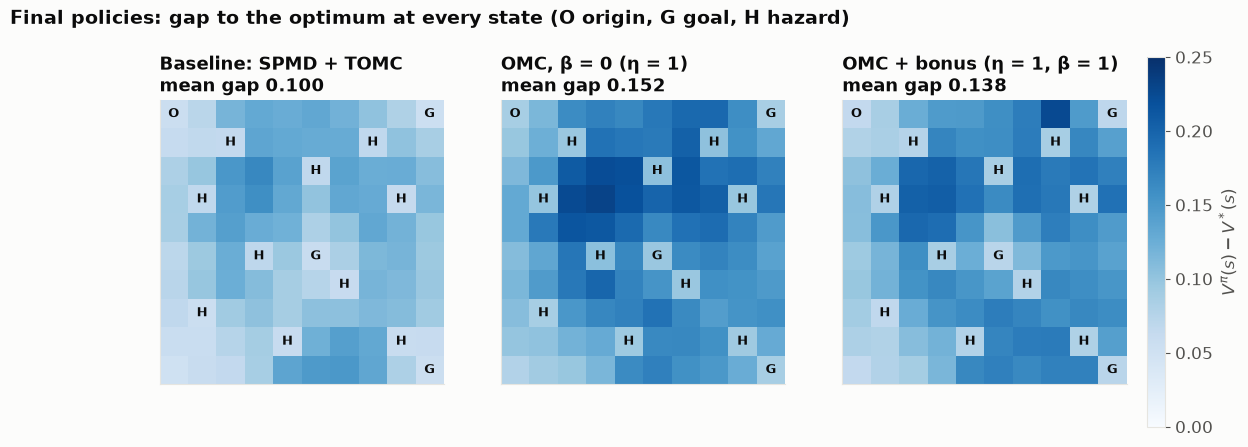

In [18]:
def draw_map(ax, cell_values, title, **image_options):
    image = ax.imshow(cell_values.reshape(N_ROWS, N_COLS), **image_options)
    for (row, col), cell in np.ndenumerate(grid):
        if cell != ".":
            ax.text(col, row, cell, ha="center", va="center", fontsize=9, fontweight="bold", color=INK)
    ax.set(title=title, xticks=[], yticks=[])
    ax.grid(False)
    return image


MAP_VMAX = None   # None: shared scale from the data. Set 0.9 to match E1's maps.

apply_plot_style()
final_gaps = {label: np.mean([on_grid(run, BUDGET, lambda v: v)[0] - V_STAR for run in runs], axis=0)
              for label, (runs, _) in METHODS.items()}
vmax = MAP_VMAX or np.ceil(max(gaps.max() for gaps in final_gaps.values()) * 20) / 20
fig, axes = plt.subplots(1, 3, figsize=(13, 4.8))
for ax, (label, gaps) in zip(axes, final_gaps.items()):
    image = draw_map(ax, gaps, f"{label}\nmean gap {gaps.mean():.3f}", cmap="Blues", vmin=0, vmax=vmax)
fig.colorbar(image, ax=axes, fraction=0.02, pad=0.02, label=r"$V^{\pi}(s) - V^*(s)$")
fig.suptitle("Final policies: gap to the optimum at every state (O origin, G goal, H hazard)",
             x=0.01, ha="left", fontsize=14, fontweight="bold")
save_figure(fig, "e3_state_maps")
plt.show()

## 12. Inspect one run

The last ten updates of the first seed of the tuned bonus run: batch length, the rarest
required probability, the Monte Carlo estimate $\widehat V_k(0)$, and the exact
$V^{\pi_k}(0)$ of the same policy.

In [19]:
run = enh3_runs["omc_bonus_tuned"][0]
n_updates = len(run["observations"])
inspection = pd.DataFrame({
    "iteration": np.arange(n_updates),
    "observations": run["observations"],
    "cumulative_observations": run["samples"][1:],
    "smallest_required_prob": run["min_required_prob"],
    "estimate_V0": run["estimate"][:-1],
    "exact_V0": run["values"][:-1, REPORT_STATE],
})
print(f"{LABELS['omc_bonus_tuned']}, seed {run['seed']}: {n_updates} updates, "
      f"unfinished tail {run['unfinished_observations']:,} observations")
print(inspection.tail(10).to_string(index=False, float_format=lambda x: f"{x:.6g}"))

OMC + bonus (η = 1, β = 1), seed 0: 13 updates, unfinished tail 663,043 observations
 iteration  observations  cumulative_observations  smallest_required_prob  estimate_V0  exact_V0
         3        191307                  1107370               0.0322099      2.11697   2.21254
         4        238197                  1345567               0.0142561       2.1405   2.16765
         5        200295                  1545862              0.00916047      2.03963   2.14493
         6        680161                  2226023              0.00346771      2.29191   2.11811
         7        656813                  2882836              0.00222525      2.07121   2.10139
         8       1685810                  4568646              0.00138908      2.00023   2.08874
         9        990132                  5558778             0.000782593      2.08774   2.07858
        10       1738814                  7297592             0.000415489      2.24957   2.07432
        11       1953687                  

## Notes and references

- Compared with the baseline, E3 changes two things: the collection rule (all pairs, no
  threshold or fallback) and the bonus. The OMC $\beta=0$ control separates them:
  *control − baseline* measures the collection rule, *bonus − control* measures the bonus.
- The bonus is a heuristic. Cumulative visit counts are not the sample size of the
  single first-visit return used for each $\widehat Q$, so no UCB confidence guarantee is
  claimed.
- Tuning uses one seed and 10% of the budget, as in the baseline and E1. The selected
  configuration is then judged on five seeds.
- The `seconds` saved with each run come from a compiled (Numba) sampler and are not
  comparable with the pure-Python baseline, E1, or E2 timings.
- C. Ju and G. Lan, *Auto-exploration for Online Reinforcement Learning*,
  arXiv:2512.06244. Their dynamic exploration time stops at the largest first-hitting
  time over pairs with $\pi(a\mid s)\ge\underline\pi$ and assigns $1/(1-\gamma)$ to the rest;
  this is the baseline's rule. E3's all-pair variant does not inherit their guarantees.
- P. Auer, N. Cesa-Bianchi, and P. Fischer, *Finite-time Analysis of the Multiarmed
  Bandit Problem*, Machine Learning 47 (2002), for the form of the bonus.

AI-use disclosure: prepared with AI assistance (ChatGPT, Claude) for implementation and
verification.